# EDA on Retail Sales Data

**Task:** DA1  
**Data provenance:** UCI Online Retail (2010–2011); dataset does not include age, gender, or product-category fields.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visual or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file():
    raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
print("DATA PROVENANCE: UCI Online Retail transactions, December 2010–December 2011.")

df = load_online_retail()

report(df)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df["InvoiceNo"] = df["InvoiceNo"].astype("string")

df = df.dropna(subset=["InvoiceDate", "Description", "CustomerID"])

df = df.loc[
        ~df["InvoiceNo"].str.startswith("C", na=False)
        & (df["Quantity"] > 0)
        & (df["UnitPrice"] > 0)
    ].copy()

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

df["Product"] = df["Description"].astype("string").str.strip()

report(df)

numeric = df[["Quantity", "UnitPrice", "Revenue"]]

stats = numeric.agg(["mean", "median", "std"]).T

stats["mode"] = numeric.mode().iloc[0]

print("Descriptive statistics:\n", stats)

DATA PROVENANCE: UCI Online Retail transactions, December 2010–December 2011.


Shape: (541909, 8)

Dtypes:
 InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Nulls:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64



Descriptive statistics:
                 count   unique                                 top    freq  \
InvoiceNo    541909.0  25900.0                            573585.0  1114.0   
StockCode      541909     4070                              85123A    2313   
Description    540455     4223  WHITE HANGING HEART T-LIGHT HOLDER    2369   
Quantity     541909.0      NaN                                 NaN     NaN   
InvoiceDate    541909      NaN                                 NaN     NaN   
UnitPrice    541909.0      NaN                                 NaN     NaN   
CustomerID   406829.0      NaN                                 NaN     NaN   
Country        541909       38                      United Kingdom  495478   

                                   mean                  min  \
InvoiceNo                           NaN                  NaN   
StockCode                           NaN                  NaN   
Description                         NaN                  NaN   
Quantity       


Nulls:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
Product        0
dtype: int64

Descriptive statistics:
                 count unique                                 top    freq  \
InvoiceNo      397884  18532                              576339     542   
StockCode      397884   3665                              85123A    2035   
Description    397884   3877  WHITE HANGING HEART T-LIGHT HOLDER    2028   
Quantity     397884.0    NaN                                 NaN     NaN   
InvoiceDate    397884    NaN                                 NaN     NaN   
UnitPrice    397884.0    NaN                                 NaN     NaN   
CustomerID   397884.0    NaN                                 NaN     NaN   
Country        397884     37                      United Kingdom  354321   
Revenue      397884.0    NaN                                 NaN     NaN   
Product        397884 

## Model Training / Analysis
Perform the task-specific analytical transformation and interpret its results; this assignment uses analysis rather than a supervised predictive model.

## Visualizations
Render task-relevant charts and interpret each result below.

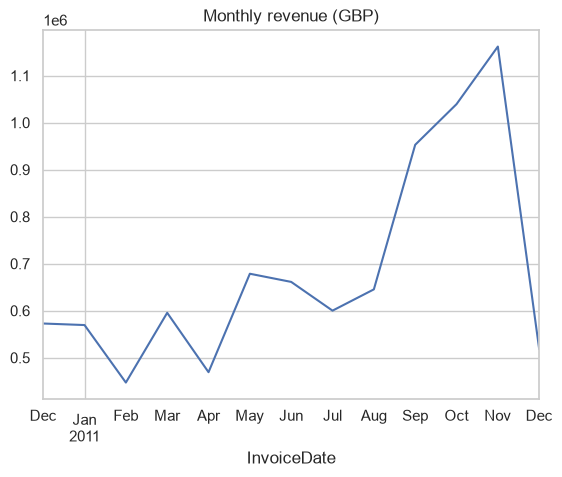

In [3]:
monthly=df.set_index("InvoiceDate").resample("ME").Revenue.sum()

quarterly=df.set_index("InvoiceDate").resample("QE").Revenue.sum()

monthly.plot(title="Monthly revenue (GBP)")

plt.show()

### Chart 1 interpretation
Monthly revenue highlights seasonality and peak periods in this 2010?2011 transaction sample. Use it as a historical inventory-planning lead, not a current forecast.

Observation: peak month was November 2011 (£1,161,817); this is historical sample activity.


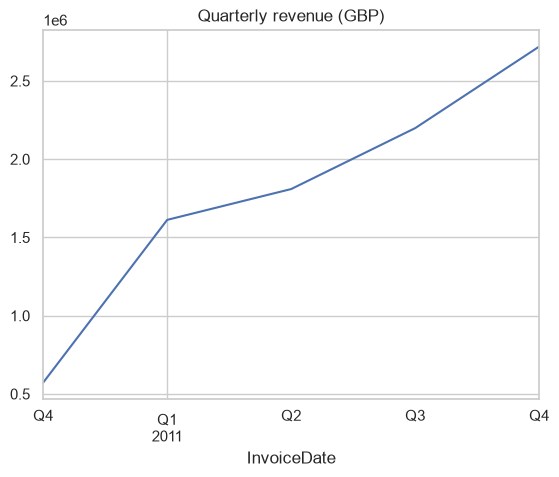

In [4]:
print(f"Observation: peak month was {monthly.idxmax():%B %Y} (£{monthly.max():,.0f}); this is historical sample activity.")

quarterly.plot(title="Quarterly revenue (GBP)")

plt.show()

### Chart 2 interpretation
Quarterly totals smooth month-to-month noise and help compare broad seasonal periods in the observation window.

Observation: peak quarter was 2011 Q4 (£2,719,329).


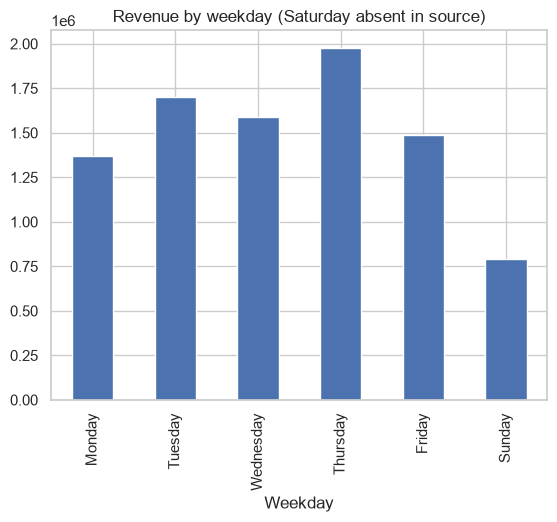

In [5]:
peak_quarter = quarterly.idxmax()

print(f"Observation: peak quarter was {peak_quarter.year} Q{peak_quarter.quarter} (£{quarterly.max():,.0f}).")

df.assign(Weekday=df["InvoiceDate"].dt.day_name()).groupby("Weekday").Revenue.sum().reindex(
        ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    ).dropna().plot.bar(title="Revenue by weekday (Saturday absent in source)")

plt.show()

### Chart 3 interpretation
Weekday totals reflect the source?s operating-day coverage; Saturday is absent, so the chart should not be interpreted as a full seven-day demand comparison.

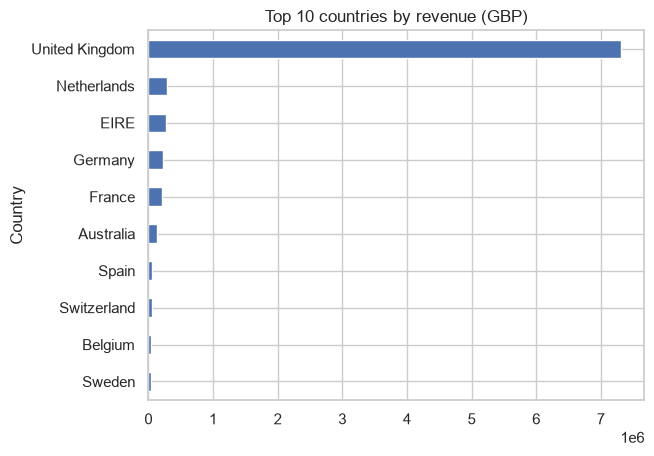

In [6]:
country_revenue = df.groupby("Country").Revenue.sum()

country_revenue.nlargest(10).sort_values().plot.barh(title="Top 10 countries by revenue (GBP)")

plt.show()

### Chart 4 interpretation
Country concentration identifies where observed revenue was recorded. Verify fulfillment costs and customer counts before prioritizing expansion.

Observation: the dataset records Country, but not individual age or gender; customer demographics cannot be computed from this source.
Observation: the dataset has item descriptions and stock codes, but no product-category field; category revenue cannot be inferred reliably.


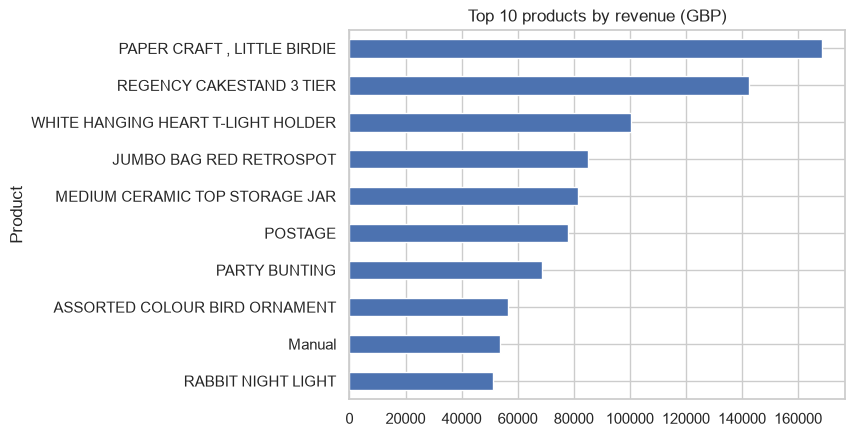

In [7]:
print("Observation: the dataset records Country, but not individual age or gender; customer demographics cannot be computed from this source.")

print("Observation: the dataset has item descriptions and stock codes, but no product-category field; category revenue cannot be inferred reliably.")

df.groupby("Product").Revenue.sum().nlargest(10).sort_values().plot.barh(title="Top 10 products by revenue (GBP)")

plt.show()

### Chart 5 interpretation
Top products can inform replenishment hypotheses, but revenue concentration alone does not capture margin, returns, or stock availability.

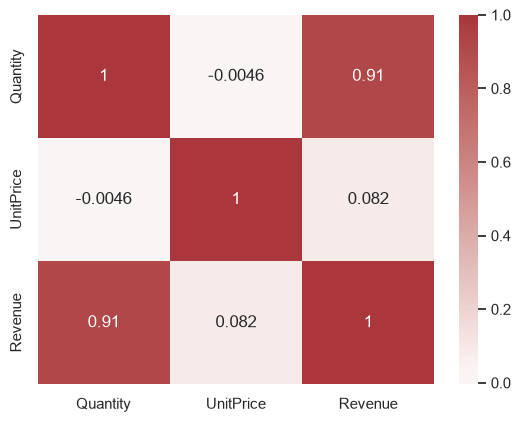

In [8]:
sns.heatmap(numeric.corr(),annot=True,cmap="vlag",center=0)

plt.show()

### Chart 6 interpretation
Quantity, unit price, and revenue are mathematically related; correlations are descriptive and partly induced by the revenue calculation.

In [9]:
print("Actionable recommendations: test replenishment for the top revenue items; evaluate seasonal stock using the monthly series; investigate country concentration before expanding. These are exploratory leads, not causal findings.")

Actionable recommendations: test replenishment for the top revenue items; evaluate seasonal stock using the monthly series; investigate country concentration before expanding. These are exploratory leads, not causal findings.


## Evaluation
Review the held-out metrics or descriptive analysis summary below. Predictive scores apply only to the documented dataset and split; non-predictive tasks report their analytical result and dataset coverage instead.

In [10]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    candidates = candidate if isinstance(candidate, list) else [candidate]
    for row in candidates:
        if isinstance(row, dict):
            metrics = {key: value for key, value in row.items()
                       if isinstance(value, (int, float, np.number))
                       and not isinstance(value, (bool, np.bool_))}
            if metrics:
                evaluation_rows.append({'model': row.get('name', variable), **metrics})
if not evaluation_rows and {'y_test', 'pred'}.issubset(globals()):
    from sklearn.metrics import precision_score, recall_score, f1_score
    evaluation_rows.append({'model': 'Fraud holdout at threshold 0.50',
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0)})
if evaluation_rows:
    evaluation = pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'), pd.DataFrame):
    evaluation = summary.copy()
elif isinstance(globals().get('profile'), pd.DataFrame):
    evaluation = profile.copy()
elif isinstance(globals().get('monthly'), pd.Series):
    evaluation = monthly.rename('revenue').to_frame()
else:
    evaluation = pd.DataFrame([{'analysis': 'Retail Sales Exploratory Analysis',
        'rows': len(df) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'columns': len(df.columns) if isinstance(globals().get('df'), pd.DataFrame) else None,
        'charts': _chart_index}])
display(evaluation)
evaluation_path = OUT_DIR / 'evaluation_summary.csv'
evaluation.to_csv(evaluation_path, index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,revenue
InvoiceDate,
2010-12-31,572713.890
2011-01-31,569445.040
2011-02-28,447137.350
2011-03-31,595500.760
2011-04-30,469200.361
2011-05-31,678594.560
2011-06-30,661213.690
2011-07-31,600091.011
2011-08-31,645343.900


Saved 6 chart(s) and evaluation summary: D:\Oasis\DataAnalytics-L1-EDARetailSales\outputs\evaluation_summary.csv
